# Crypto Risk Factors — v2 Robustness Checks

Extends v1 with weekly vs. daily horizons, one-period lagged factors, market-return and momentum controls, and Newey-West (HAC) standard errors.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from datetime import datetime, timedelta
import os
import warnings
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS
warnings.filterwarnings('ignore')

# Data download with multiple frequencies
tickers = ['BTC-USD', 'ETH-USD', 'BNB-USD']
end_date = datetime.today()
start_date = end_date - timedelta(days=3*365) 

data_daily = {}
data_weekly = {}

for ticker in tickers:  
    temp_data = yf.download(ticker, start=start_date, end=end_date, interval='1d')
    if not temp_data.empty:
        data_daily[ticker] = temp_data
        data_weekly[ticker] = temp_data.resample('W').last()

close_prices_daily = pd.DataFrame()
close_prices_weekly = pd.DataFrame()
volumes_daily = pd.DataFrame()

for ticker, df in data_daily.items():
    close_prices_daily[ticker] = df['Close']
    volumes_daily[ticker] = df['Volume']

for ticker, df in data_weekly.items():
    close_prices_weekly[ticker] = df['Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [2]:
def compute_required_risk_metrics(close_prices, volumes, window=30, frequency='daily'):
    """
    Compute risk metrics for different frequencies
    """
    if frequency == 'daily':
        annualization_factor = 365
        window_adjusted = window
    else:
        annualization_factor = 52
        window_adjusted = max(4, window // 5)

    returns = np.log(close_prices / close_prices.shift(1)).dropna()
    
    market_returns = returns.mean(axis=1)
    
    if frequency == 'daily':
        momentum_period = 20
    else:
        momentum_period = 4
    
    momentum = close_prices.pct_change(momentum_period).shift(1)
    
    risk_metrics = {}
    
    for ticker in close_prices.columns:
        ticker_returns = returns[ticker]
        
        rolling_vol = ticker_returns.rolling(window_adjusted).std() * np.sqrt(annualization_factor)
        rolling_skew = ticker_returns.rolling(window_adjusted).apply(skew, raw=True)
        rolling_kurt = ticker_returns.rolling(window_adjusted).apply(kurtosis, raw=True)
        
        if frequency == 'daily':
            vol_data = volumes[ticker].dropna()
            price_data = close_prices[ticker].dropna()
            common_idx = ticker_returns.index.intersection(vol_data.index)
            
            if not common_idx.empty:
                dollar_volume = (vol_data * price_data).reindex(common_idx)
                amihud_ratio = (np.abs(ticker_returns) / dollar_volume).rolling(window_adjusted).mean()
            else:
                amihud_ratio = pd.Series(index=ticker_returns.index, dtype=float)
        else:
            amihud_ratio = ticker_returns.rolling(window_adjusted).std()
        
        vol_lagged = rolling_vol.shift(1)
        skew_lagged = rolling_skew.shift(1)
        kurt_lagged = rolling_kurt.shift(1)
        amihud_lagged = amihud_ratio.shift(1)
        
        risk_df = pd.DataFrame({
            'volatility': rolling_vol,
            'skewness': rolling_skew,
            'kurtosis': rolling_kurt,
            'amihud_ratio': amihud_ratio,
            'volatility_lagged': vol_lagged,
            'skewness_lagged': skew_lagged,
            'kurtosis_lagged': kurt_lagged,
            'amihud_lagged': amihud_lagged,
            'market_returns': market_returns,
            'momentum': momentum[ticker] if ticker in momentum.columns else pd.Series(index=ticker_returns.index)
        })
        
        risk_df = risk_df.dropna(thresh=5)
        risk_metrics[ticker] = risk_df
    
    return risk_metrics, returns

def enhanced_regression_analysis(returns, risk_metrics, use_newey_west=True, frequency='daily'):
    """
    Enhanced regression with Newey-West standard errors
    """
    results = {}
    
    for ticker in returns.columns:
        if ticker not in risk_metrics:
            continue
            
        ticker_returns = returns[ticker].dropna()
        risk_data = risk_metrics[ticker].dropna()
        
        common_idx = ticker_returns.index.intersection(risk_data.index)
        X = risk_data.loc[common_idx]
        y = ticker_returns.loc[common_idx]
        
        if len(X) < 20:
            continue
            
        specifications = {
            'baseline': ['volatility', 'skewness', 'kurtosis', 'amihud_ratio'],
            'lagged': ['volatility_lagged', 'skewness_lagged', 'kurtosis_lagged', 'amihud_lagged'],
            'with_controls': ['volatility_lagged', 'skewness_lagged', 'kurtosis_lagged', 
                            'amihud_lagged', 'market_returns', 'momentum']
        }
        
        ticker_results = {}
        
        for spec_name, features in specifications.items():
            available_features = [f for f in features if f in X.columns and X[f].notna().any()]
            
            if len(available_features) < 2:
                continue
                
            X_spec = X[available_features].dropna()
            y_spec = y.loc[X_spec.index]
            
            if len(X_spec) < 10:
                continue
            
            try:
                X_spec_const = sm.add_constant(X_spec)
                
                if frequency == 'daily':
                    nw_lags = int(4 * (len(y_spec) / 100) ** (2/9))
                else:
                    nw_lags = int(2 * (len(y_spec) / 100) ** (2/9))
                
                model = sm.OLS(y_spec, X_spec_const)
                fitted_model = model.fit(cov_type='HAC', cov_kwds={'maxlags': nw_lags})
                
                ticker_results[spec_name] = {
                    'coefficients': pd.Series(fitted_model.params[1:], index=available_features),
                    'r_squared': fitted_model.rsquared,
                    'intercept': fitted_model.params[0],
                    'p_values': pd.Series(fitted_model.pvalues[1:], index=available_features),
                    't_stats': pd.Series(fitted_model.tvalues[1:], index=available_features),
                    'nw_lags': nw_lags,
                    'n_obs': len(y_spec)
                }
                
            except Exception as e:
                continue
        
        if ticker_results:
            results[ticker] = ticker_results
    
    return results

def create_r_squared_visualization(regression_results_daily, regression_results_weekly):
    """
    Create R-squared comparison visualization
    """
    r2_data = []
    for freq, results in [('Daily', regression_results_daily), ('Weekly', regression_results_weekly)]:
        for ticker, spec_results in results.items():
            for spec_name, result in spec_results.items():
                r2_data.append({
                    'Frequency': freq,
                    'Ticker': ticker,
                    'Specification': spec_name,
                    'R_squared': result['r_squared']
                })
    
    r2_df = pd.DataFrame(r2_data)
    if not r2_df.empty:
        plt.figure(figsize=(12, 6))
        sns.barplot(data=r2_df, x='Specification', y='R_squared', hue='Frequency')
        plt.title('R-squared Comparison: Daily vs Weekly Frequency')
        plt.xticks(rotation=45)
        plt.ylabel('R-squared')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        print("\nR-squared Summary Statistics:")
        print("=" * 50)
        summary = r2_df.groupby(['Specification', 'Frequency'])['R_squared'].agg(['mean', 'std', 'min', 'max']).round(4)
        print(summary)

def display_enhanced_results(regression_results, frequency_label):
    """
    Display enhanced regression results
    """
    print(f"\n{'='*60}")
    print(f"REGRESSION RESULTS - {frequency_label.upper()} FREQUENCY")
    print(f"{'='*60}")
    
    if not regression_results:
        print("No results available")
        return
    
    for ticker, spec_results in regression_results.items():
        print(f"\n{ticker}:")
        print("-" * 40)
        
        for spec_name, result in spec_results.items():
            print(f"\n  Specification: {spec_name}")
            print(f"  R-squared: {result['r_squared']:.4f}")
            print(f"  Observations: {result.get('n_obs', 'N/A')}")
            if 'nw_lags' in result:
                print(f"  Newey-West lags: {result['nw_lags']}")
            
            coef_df = pd.DataFrame({
                'Coefficient': result['coefficients'],
                't-Statistic': result['t_stats'],
                'p-Value': result['p_values']
            })
            
            display_df = coef_df.copy()
            display_df['Coefficient'] = display_df['Coefficient'].apply(lambda x: f"{x:.6f}")
            display_df['t-Statistic'] = display_df['t-Statistic'].apply(lambda x: f"{x:.4f}")
            display_df['p-Value'] = display_df['p-Value'].apply(lambda x: f"{x:.4f}")
            
            def add_stars(p_val_str):
                p_val = float(p_val_str)
                if p_val < 0.01:
                    return f"{p_val_str}***"
                elif p_val < 0.05:
                    return f"{p_val_str}**"
                elif p_val < 0.1:
                    return f"{p_val_str}*"
                else:
                    return p_val_str
            
            display_df['p-Value'] = display_df['p-Value'].apply(add_stars)
            print(display_df.to_string())


REGRESSION RESULTS - DAILY FREQUENCY

BTC-USD:
----------------------------------------

  Specification: baseline
  R-squared: 0.0069
  Observations: 1064
  Newey-West lags: 6
             Coefficient t-Statistic   p-Value
volatility      0.002613      0.5505    0.5819
skewness        0.002593      2.5584  0.0105**
kurtosis        0.000054      0.1408    0.8881
amihud_ratio    0.000000      0.5246    0.5999

  Specification: lagged
  R-squared: 0.0002
  Observations: 1064
  Newey-West lags: 6
                  Coefficient t-Statistic p-Value
volatility_lagged   -0.000640     -0.1359  0.8919
skewness_lagged      0.000380      0.4118  0.6805
kurtosis_lagged      0.000127      0.3819  0.7025
amihud_lagged       -0.000000     -0.1386  0.8897

  Specification: with_controls
  R-squared: 0.8107
  Observations: 1064
  Newey-West lags: 6
                  Coefficient t-Statistic    p-Value
volatility_lagged    0.000920      0.4226     0.6726
skewness_lagged      0.000305      0.6650     0.50

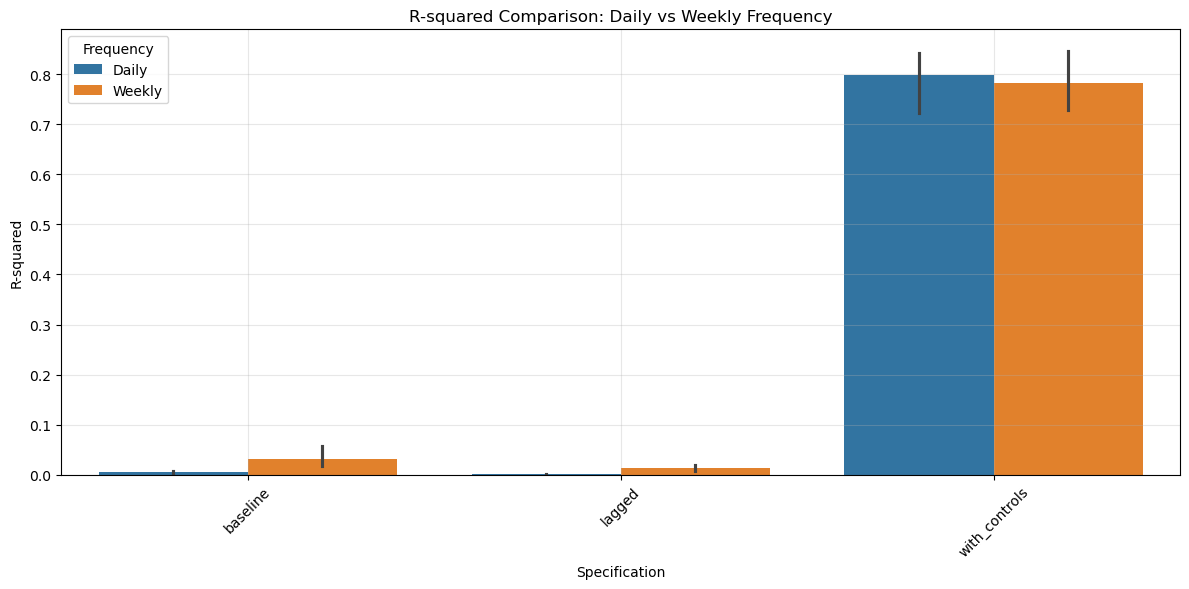


R-squared Summary Statistics:
                           mean     std     min     max
Specification Frequency                                
baseline      Daily      0.0061  0.0014  0.0045  0.0069
              Weekly     0.0316  0.0226  0.0170  0.0576
lagged        Daily      0.0008  0.0009  0.0002  0.0018
              Weekly     0.0135  0.0061  0.0074  0.0196
with_controls Daily      0.7976  0.0692  0.7228  0.8593
              Weekly     0.7821  0.0602  0.7283  0.8471


In [3]:
if __name__ == "__main__":
       
    # Daily frequency analysis
    risk_metrics_daily, returns_daily = compute_required_risk_metrics(
        close_prices_daily, volumes_daily, frequency='daily'
    )
    regression_results_daily = enhanced_regression_analysis(
        returns_daily, risk_metrics_daily, use_newey_west=True, frequency='daily'
    )
    
    # Weekly frequency analysis
    close_prices_weekly_fixed = close_prices_daily.resample('W').last()
    volumes_weekly_fixed = volumes_daily.resample('W').sum()
    
    risk_metrics_weekly, returns_weekly = compute_required_risk_metrics(
        close_prices_weekly_fixed, volumes_weekly_fixed, frequency='weekly'
    )
    
    regression_results_weekly = enhanced_regression_analysis(
        returns_weekly, risk_metrics_weekly, use_newey_west=True, frequency='weekly'
    )
    
    display_enhanced_results(regression_results_daily, "daily")
    display_enhanced_results(regression_results_weekly, "weekly")
    
    print("\nR-SQUARED COMPARISON VISUALIZATION")
    create_r_squared_visualization(regression_results_daily, regression_results_weekly)